# Cross-Network Zeek Intrusion Detection Report

**Question:** *Does a flow-based ML model trained on public Zeek datasets generalize to an unseen network?*

### Experiment Overview

| Section | Training set | Tested on |
|---|---|---|
| 1 | UNSW-NB15 | CIC-IDS2017, UWF-2024, UWF-2025, AIT-LDSv2 |
| 2 | CIC-IDS2017 | UNSW-NB15, UWF-2024, UWF-2025, AIT-LDSv2 |
| 3 | CIC-IDS2017 + UNSW-NB15 | UWF-2024, UWF-2025, AIT-LDSv2 |
| 4 | CIC-IDS2017 + UWF-2024 | UNSW-NB15, UWF-2025 *(same lab)*, AIT-LDSv2 |
| 6 | CIC-IDS2017 + UWF-2024 + AIT (half A) | All 4 public test sets + 4 unseen AIT networks (half B) |

### Methodology

- **Datasets (5 Zeek `conn.log` captures):**
  - *Public lab benchmarks:* **UNSW-NB15** (official Zeek logs), **CIC-IDS2017** (5-day capture relabeled from UNB's attack schedule), **UWF-2024** & **UWF-2025** (University of West Florida captures).
  - *Enterprise simulation:* **AIT-LDSv2** (8 simulated company networks: half A = `fox, harrison, santos, shaw`; half B = `russellmitchell, wardbeck, wheeler, wilson`).
- **Features & 60 s Windowing:** Raw IPs, ports, and timestamps are excluded so models cannot memorize addresses.
  - **Per-flow (14 features):** 3 categoricals (`proto`, `service`, `conn_state`), 8 raw Zeek counters (`duration`, `orig_bytes`, `resp_bytes`, `missed_bytes`, `orig_pkts`, `orig_ip_bytes`, `resp_pkts`, `resp_ip_bytes`), and 3 flow ratios (`orig_bytes_per_pkt`, `resp_bytes_per_pkt`, `byte_ratio`).
  - **Windowed (19 features):** Per-flow + 5 per-source-host stats aggregated over fixed **60-second** windows (`ts // 60`, grouped per capture): connection count, unique destination ports, failed-connection ratio, total `orig_bytes`, and total `resp_bytes`.
- **Time-Block Split (80/20):** Every dataset is grouped into **30-minute** time blocks (`ts // 1800`); 20% of whole blocks are randomly held out for testing (`SEED = 42`). Splitting by block prevents neighboring flows from the same attack leaking across train and test.
- **1M Stratified Cap:** When a training set exceeds 1,000,000 rows, it is randomly subsampled to **1M rows** stratified by `label` — preserving each dataset's natural attack share and proportions while keeping training fast. Test splits are never capped.
- **Target-Network Normal Sample (`+10k normal`):** 10,000 benign (`label == 0`) connections are randomly drawn from the **test network's 80% training split** (time-disjoint from its 20% test split) and appended *after* the 1M cap.
- **Model & Metrics:** `HistGradientBoostingClassifier` (`max_iter=200`, `OneHotEncoder` for categoricals), evaluated at threshold **0.5** using **ROC-AUC** (threshold-free ranking), **F1**, **Precision**, **Recall**, and **FPR** (false positive rate).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, precision_score, roc_auc_score

from cybershield.ml.train_zeek import fit_zeek_model
from cybershield.ml.zeek_features import (
    ZEEK_CAT_COLS, ZEEK_FLOW_RATIO_COLS, ZEEK_HOST_CTX_COLS, ZEEK_RAW_NUM_COLS,
    load_ait_lds_zeek, load_cic2017_zeek, load_unsw_official_zeek, load_uwf_zeek,
)

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
MAX_TRAIN = 1_000_000
EXTRA_NORMAL = 10_000
PER_FLOW = ZEEK_CAT_COLS + ZEEK_RAW_NUM_COLS + ZEEK_FLOW_RATIO_COLS
WINDOWED = PER_FLOW + ZEEK_HOST_CTX_COLS
METRICS = ["ROC-AUC", "F1", "Precision", "Recall", "FPR"]
VARIANTS = ["Per-flow", "Windowed", "Windowed +10k normal"]


def split(df, extra_cols=()):
    """80/20 split by 30-minute time blocks."""
    cols = WINDOWED + ["label", "ts"] + list(extra_cols)
    df = df[cols].reset_index(drop=True)
    block = (df.ts // 1800).astype("int64")
    test_blocks = np.random.default_rng(SEED).choice(block.unique(), size=int(block.nunique() * 0.2), replace=False)
    is_test = block.isin(test_blocks)
    return {"train": df[~is_test].reset_index(drop=True), "test": df[is_test].reset_index(drop=True)}


def subsample(df, max_rows=MAX_TRAIN):
    """Cap training rows at max_rows while preserving the natural class ratio."""
    if len(df) <= max_rows:
        return df
    frac = max_rows / len(df)
    parts = [g.sample(n=max(1, int(round(len(g) * frac))), random_state=SEED) for _, g in df.groupby("label")]
    return pd.concat(parts, ignore_index=True)


AIT = load_ait_lds_zeek()
DATA = {
    "UNSW-NB15": split(load_unsw_official_zeek()),
    "CIC-IDS2017": split(load_cic2017_zeek()),
    "UWF-2024": split(pd.concat([load_uwf_zeek("UWF-ZeekData24"), load_uwf_zeek("UWF-ZeekDataFall24-2")], ignore_index=True)),
    "UWF-2025": split(pd.concat([load_uwf_zeek("UWF-ZeekDataSum25-1"), load_uwf_zeek("UWF-ZeekDataSum25-2")], ignore_index=True)),
    "AIT-LDSv2": split(AIT, extra_cols=("scenario", "attack_type")),
}
NAMES = list(DATA)
pd.DataFrame({n: {"Train rows (raw)": f"{len(d['train']):,}", "Test rows": f"{len(d['test']):,}",
                  "Test attack share": f"{d['test'].label.mean():.1%}"} for n, d in DATA.items()}).T

,Train rows (raw),Test rows,Test attack share
UNSW-NB15,"1,566,238","356,330",4.0%
CIC-IDS2017,"1,749,268","359,970",5.7%
UWF-2024,"4,079,392","720,753",35.2%
UWF-2025,"2,503,659","514,997",41.2%
AIT-LDSv2,"2,055,818","443,009",19.2%


In [2]:
TRAININGS = {
    "UNSW-NB15": ["UNSW-NB15"],
    "CIC-IDS2017": ["CIC-IDS2017"],
    "CIC-IDS2017 + UNSW-NB15": ["CIC-IDS2017", "UNSW-NB15"],
    "CIC-IDS2017 + UWF-2024": ["CIC-IDS2017", "UWF-2024"],
}


def score(y, probs):
    y = np.asarray(y)
    flagged = probs >= 0.5
    return {
        "ROC-AUC": roc_auc_score(y, probs) if len(np.unique(y)) > 1 else np.nan,
        "F1": f1_score(y, flagged, zero_division=0),
        "Precision": precision_score(y, flagged, zero_division=0),
        "Recall": flagged[y == 1].mean(),
        "FPR": flagged[y == 0].mean(),
    }


def metrics(y, model, X):
    probs = model.predict_proba(X)[:, 1]
    return score(y, probs), probs


MODELS = {}
AIT_HITS = {}


def run(training):
    raw_train = pd.concat([DATA[n]["train"][WINDOWED + ["label"]] for n in TRAININGS[training]], ignore_index=True)
    train = subsample(raw_train)
    tests = [n for n in NAMES if n not in TRAININGS[training]]
    base = {
        "Per-flow": (fit_zeek_model(train, PER_FLOW), PER_FLOW),
        "Windowed": (fit_zeek_model(train, WINDOWED), WINDOWED),
    }
    MODELS[training] = base
    rows = []
    for t in tests:
        test, own = DATA[t]["test"], DATA[t]["train"]
        extra = own[own.label == 0].sample(EXTRA_NORMAL, random_state=SEED)[WINDOWED + ["label"]]
        plus = fit_zeek_model(pd.concat([train, extra], ignore_index=True), WINDOWED)
        for variant, (model, feats) in {**base, "Windowed +10k normal": (plus, WINDOWED)}.items():
            m, probs = metrics(test.label, model, test[feats])
            rows.append({"Training": training, "Test network": t, "Variant": variant, **m})
            if t == "AIT-LDSv2" and training == "CIC-IDS2017 + UWF-2024":
                a = test[test.label == 1]
                AIT_HITS[variant] = a[["attack_type"]].assign(hit=probs[test.label.to_numpy() == 1] >= 0.5, Variant=variant)
    return rows


RES = pd.DataFrame([r for training in TRAININGS for r in run(training)])
RES["Variant"] = pd.Categorical(RES.Variant, VARIANTS)
RES["Training"] = pd.Categorical(RES.Training, list(TRAININGS))
RES["Test network"] = pd.Categorical(RES["Test network"], NAMES)

In [3]:
VARIANT_STYLE = {
    "Per-flow":             {"color": "#9ecae1", "marker": "o", "size": 65},
    "Windowed":             {"color": "#2171b5", "marker": "s", "size": 65},
    "Windowed +10k normal": {"color": "#e6550d", "marker": "D", "size": 65},
}
TRAIN_STYLE = {
    "UNSW-NB15":               {"color": "#7f7f7f", "marker": "o", "size": 65},
    "CIC-IDS2017":             {"color": "#2171b5", "marker": "s", "size": 65},
    "CIC-IDS2017 + UNSW-NB15": {"color": "#756bb1", "marker": "^", "size": 70},
    "CIC-IDS2017 + UWF-2024":  {"color": "#e6550d", "marker": "D", "size": 65},
}
MIX_STYLE = {
    "CIC + UWF-2024":           {"color": "#2171b5", "marker": "o", "size": 65},
    "CIC + UWF-2024 + AIT (A)": {"color": "#e6550d", "marker": "D", "size": 65},
}


def dot_panels(df, column, styles, title):
    """Connected horizontal dot-plot: one panel per metric, y = test network."""
    networks = [n for n in df["Test network"].cat.categories if n in df["Test network"].values]
    y_pos = np.arange(len(networks))[::-1]
    fig, axes = plt.subplots(1, len(METRICS), figsize=(17.5, max(2.8, 0.55 * len(networks) + 1.4)), sharey=True)

    for ax, m in zip(axes, METRICS):
        piv = df.pivot_table(index="Test network", columns=column, values=m, observed=True).reindex(networks)
        for idx, net in enumerate(networks):
            vals = piv.loc[net].dropna()
            if len(vals) >= 2:
                ax.hlines(y_pos[idx], vals.min(), vals.max(), color="#999999", lw=1.6, alpha=0.6, zorder=1)
        for key, st in styles.items():
            if key in piv.columns:
                ax.scatter(piv[key].values, y_pos, label=key, color=st["color"], marker=st["marker"],
                           s=st["size"], edgecolors="white", linewidths=0.7, zorder=3)
        ax.set_title(m + (" ↓" if m == "FPR" else " ↑"), fontsize=10.5, fontweight="bold")
        ax.set_xlim(-0.04, 1.04)
        ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
        ax.set_xticklabels(["0", ".25", ".50", ".75", "1"], fontsize=8.5)
        ax.grid(axis="x", alpha=0.25, linestyle="--")
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    axes[0].set_yticks(y_pos)
    axes[0].set_yticklabels(networks, fontsize=9.5)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=len(labels), frameon=False,
               bbox_to_anchor=(0.5, -0.06), fontsize=9.5)
    fig.suptitle(title, fontsize=12.5, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()


def clean_table(df):
    """Clean uncolored table with Average rows at the bottom; bolds the best variant per group."""
    t = df.set_index(["Test network", "Variant"])[METRICS].sort_index()
    avg = df.groupby("Variant", observed=True)[METRICS].mean()
    avg.index = pd.MultiIndex.from_product([["Average"], avg.index], names=["Test network", "Variant"])
    t = pd.concat([t, avg])

    def bold_best(col):
        out = []
        for net, grp in col.groupby(level=0, sort=False, observed=True):
            best = grp.min() if col.name == "FPR" else grp.max()
            out.extend(["font-weight: 700" if v == best else "" for v in grp])
        return out

    n_rows = len(t)
    avg_start = n_rows - len(avg) + 1
    return (t.style
            .format("{:.2f}")
            .format("{:.3f}", subset=["FPR"])
            .apply(bold_best, axis=0)
            .set_table_styles([
                {"selector": "th", "props": [("text-align", "left"), ("padding", "5px 10px")]},
                {"selector": "td", "props": [("text-align", "right"), ("padding", "4px 10px")]},
                {"selector": "tr:nth-child(3n) td, tr:nth-child(3n) th", "props": [("border-bottom", "1px solid #555")]},
                {"selector": f"tbody tr:nth-child({avg_start}) td, tbody tr:nth-child({avg_start}) th",
                 "props": [("border-top", "2px solid #888")]},
            ]))


def section(training):
    d = RES[RES.Training == training]
    dot_panels(d, "Variant", VARIANT_STYLE, f"Trained on {training}")
    return clean_table(d)

## 1. Train on UNSW-NB15

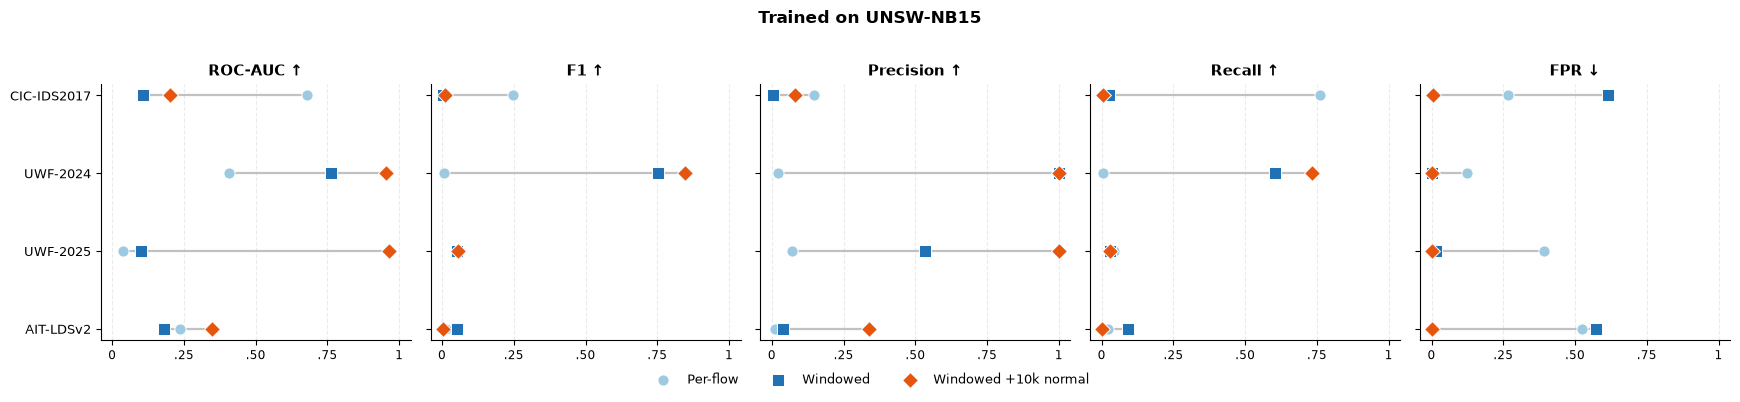

In [4]:
section("UNSW-NB15")

- **UWF-2024:** Windowed works well (F1 0.75, FPR 0.000); adding **+10k normal** lifts it further to **F1 0.85, ROC-AUC 0.95** (recall 0.73, precision 1.00). Per-flow fails (F1 0.01).
- **CIC-IDS2017:** Per-flow catches 76% of attacks but flags 27% of normal traffic (F1 0.25). Windowed collapses (ROC-AUC 0.11, FPR 0.614).
- **UWF-2025:** Looks broken at threshold 0.5 (F1 0.06, recall 0.03), **but +10k normal jumps ROC-AUC from 0.10 → 0.96** — the model separates attacks from normal, its scores just sit below 0.5.
- **AIT-LDSv2:** Fails across all variants (F1 ≤ 0.05, ROC-AUC ≤ 0.35).

## 2. Train on CIC-IDS2017

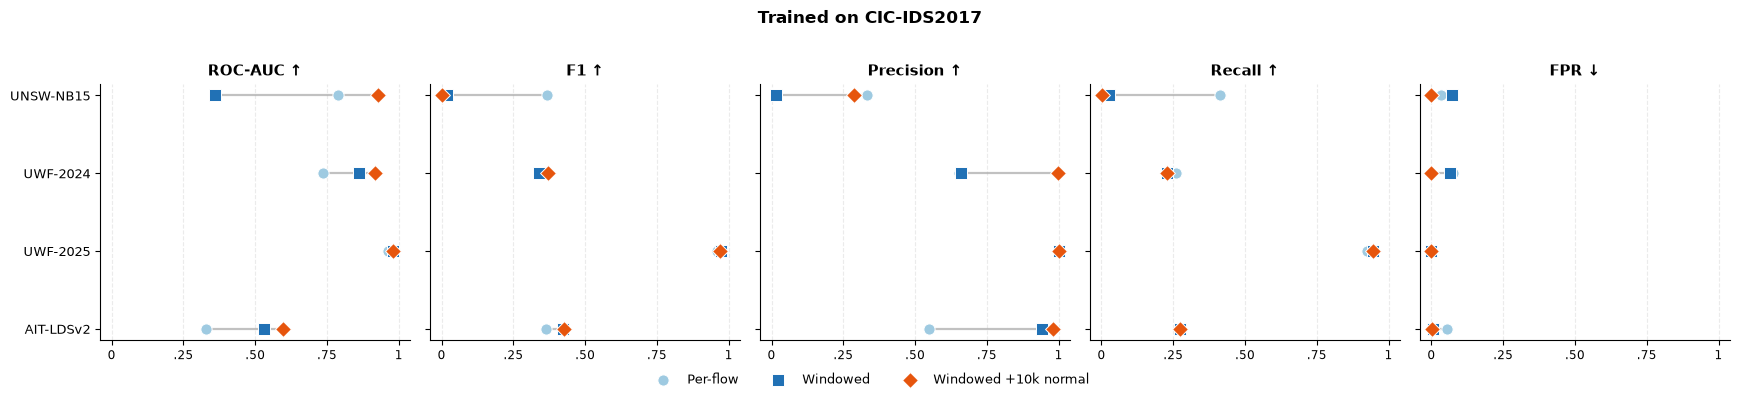

In [5]:
section("CIC-IDS2017")

- **UWF-2025:** Near-perfect across all variants (**F1 0.96–0.97, ROC-AUC 0.96–0.98, FPR 0.000**), because its test attacks are mostly scans that CIC-IDS2017 already covers.
- **UNSW-NB15:** Per-flow is modest (F1 0.37, ROC-AUC 0.79). Windowed fails (F1 0.02, ROC-AUC 0.36), **but +10k normal pushes ROC-AUC to 0.93** while dropping F1 to 0.00 (scores are well-ranked, just below 0.5).
- **UWF-2024:** Low recall (~0.23–0.26, F1 0.34–0.37), though **+10k normal** cuts FPR from 0.063 → 0.000 (precision 1.00, ROC-AUC 0.92).
- **AIT-LDSv2:** Windowed +10k normal gets **precision 0.98, FPR 0.001**, but recall stops at **0.27** (F1 0.43, ROC-AUC 0.60) because it misses unseen attack types like DNS exfiltration.

## 3. Train on CIC-IDS2017 + UNSW-NB15

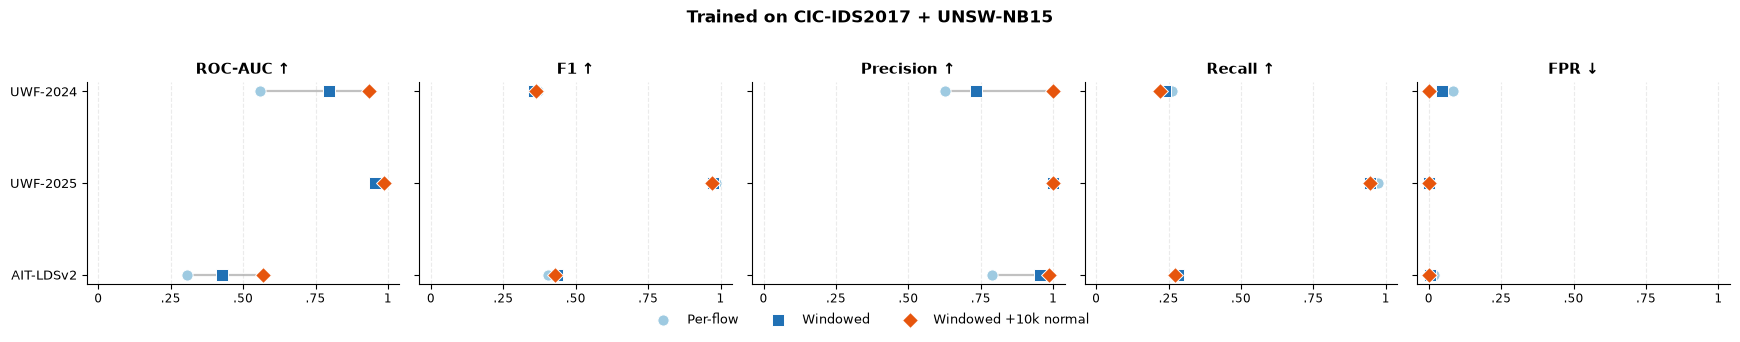

In [6]:
section("CIC-IDS2017 + UNSW-NB15")

- **Almost identical to CIC-IDS2017 alone** on every test set (within 0.01–0.02 F1 on UWF-2024, UWF-2025, and AIT-LDSv2).
- Adding UNSW-NB15 to CIC-IDS2017 does not improve generalization to unseen networks.

## 4. Train on CIC-IDS2017 + UWF-2024

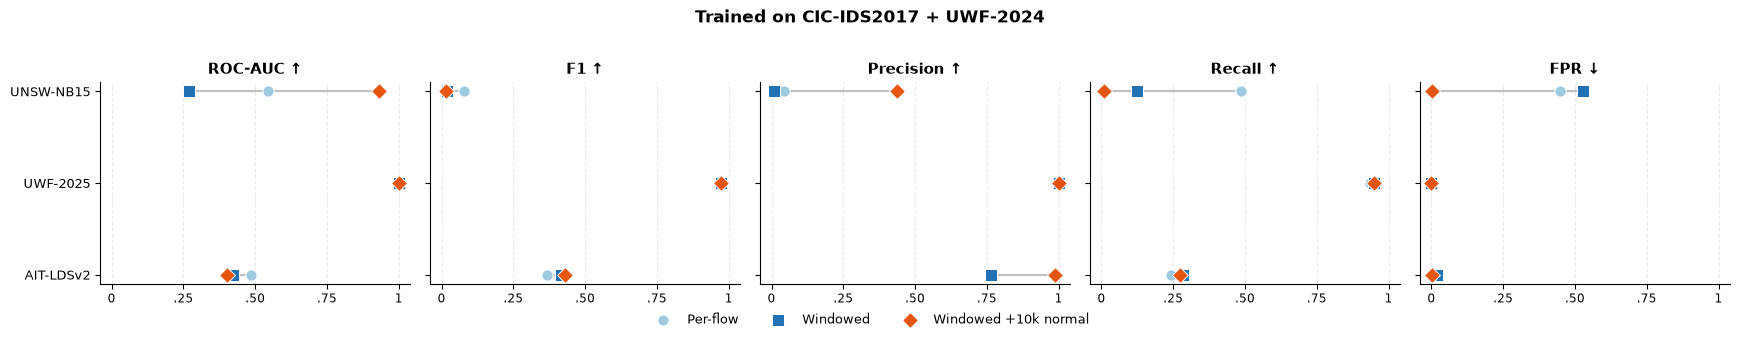

In [7]:
section("CIC-IDS2017 + UWF-2024")

- **UWF-2025:** Near-perfect (**ROC-AUC 1.00, F1 0.97, FPR 0.000**), same as CIC-IDS2017 alone.
- **UNSW-NB15:** Adding UWF-2024 **hurts** raw false alarms (FPR jumps to 0.449–0.527 vs 0.035–0.072 for CIC alone). **+10k normal** removes the false alarms (FPR 0.000) and raises **ROC-AUC to 0.93**, again leaving attack scores below 0.5 (F1 0.01).
- **AIT-LDSv2:** Same pattern as CIC-IDS2017 alone — **F1 0.43, precision 0.99, FPR 0.001, recall 0.27** with +10k normal. The attack-type breakdown below explains why recall stops at 27%.

### Recall per attack type on AIT-LDSv2 (CIC-IDS2017 + UWF-2024 model)

Uses the already-fitted section 4 models on AIT-LDSv2's 20% test split (no extra training). Steps with fewer than 100 test connections are grouped as "other steps".

In [8]:
h = pd.concat(AIT_HITS.values(), ignore_index=True)
n = h[h.Variant == "Windowed"].attack_type.value_counts()
h["Attack"] = h.attack_type.where(h.attack_type.map(n) >= 100, "other steps")
r = h.pivot_table(index="Attack", columns="Variant", values="hit", aggfunc="mean", observed=True)[VARIANTS]
r.insert(0, "Connections", h[h.Variant == "Windowed"].Attack.value_counts())
r = r.sort_values("Connections", ascending=False)
avg_row = pd.DataFrame(
    [{"Connections": int(r["Connections"].sum()), **{v: r[v].mean() for v in VARIANTS}}],
    index=pd.Index(["Average (macro)"], name="Attack"),
)
r = pd.concat([r, avg_row])
(r.style
 .format("{:.2f}", subset=VARIANTS)
 .format("{:,.0f}", subset=["Connections"])
 .set_table_styles([
     {"selector": "th", "props": [("text-align", "left"), ("padding", "5px 10px")]},
     {"selector": "td", "props": [("text-align", "right"), ("padding", "4px 10px")]},
     {"selector": "tbody tr:last-child td, tbody tr:last-child th",
      "props": [("border-top", "2px solid #888"), ("font-weight", "700")]},
 ]))

,Connections,Per-flow,Windowed,Windowed +10k normal
Attack,,,,
dns_exfiltration,"57,565",0.00,0.00,0.00
host_discover_local,"15,847",1.00,1.00,1.00
service_scan,"5,595",0.79,0.99,0.99
dirb_scan,"4,077",0.00,0.22,0.00
dns_brute_force,"1,951",0.21,1.00,1.00
other steps,70,0.31,0.24,0.23
Average (macro),"85,105",0.39,0.58,0.54


## 5. Comparing the training sets

Same connected dot-plot, now comparing the four training sets side by side. Top: **Windowed**. Bottom: **Windowed +10k normal**. A missing dot means that dataset was part of training.

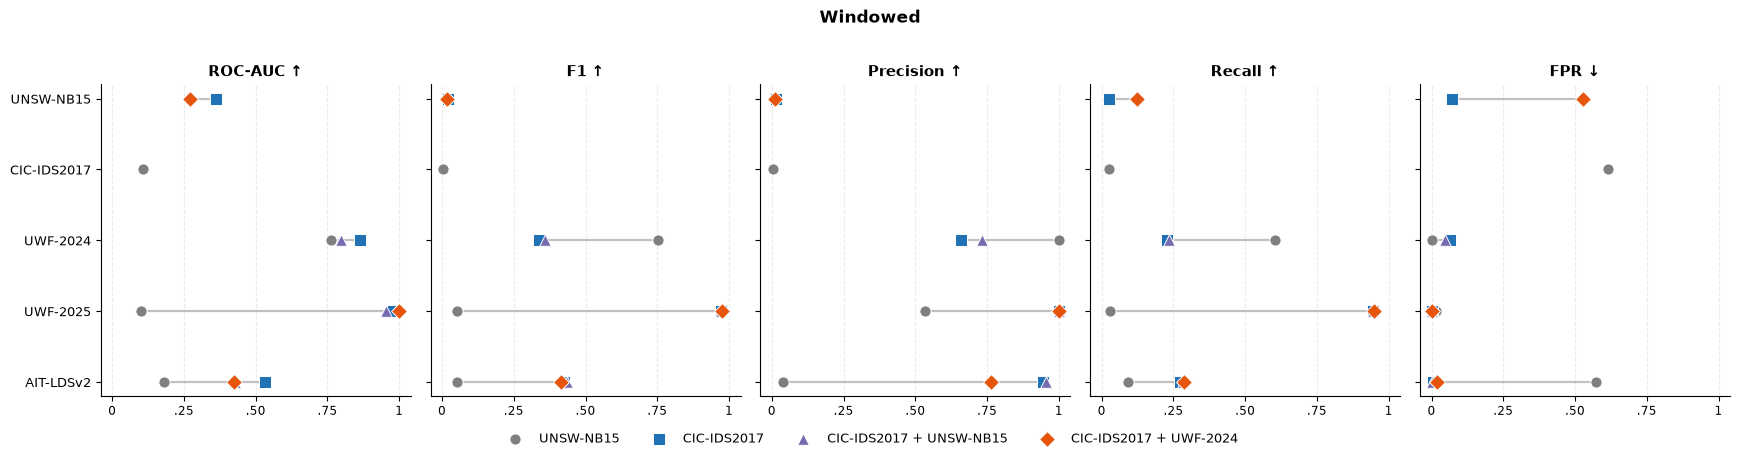

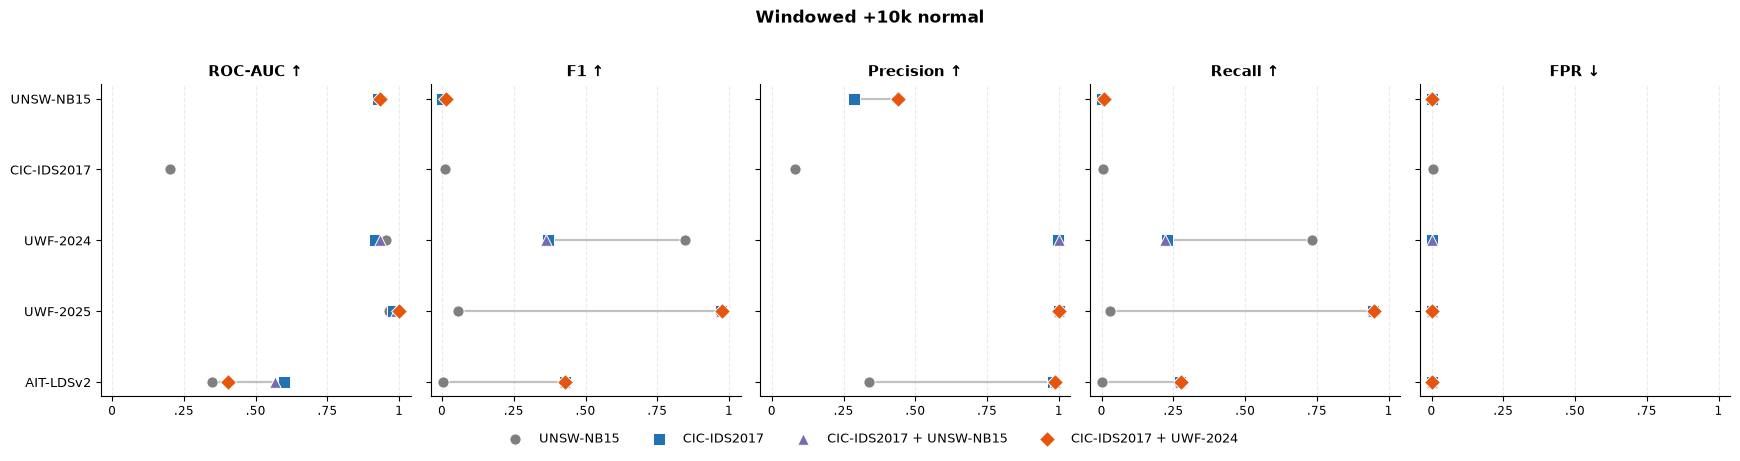

In [9]:
for variant in ["Windowed", "Windowed +10k normal"]:
    dot_panels(RES[RES.Variant == variant], "Training", TRAIN_STYLE, variant)

- **No public training set works on every unseen network** at threshold 0.5.
- **Adding a second public dataset didn't help:** CIC + UNSW matches CIC alone; CIC + UWF-2024 hurts raw FPR on UNSW-NB15.
- **ROC-AUC exposes a huge threshold problem:** with **+10k normal**, several "failed" pairs (F1 0.00–0.06) actually achieve **ROC-AUC 0.93–0.96** (CIC → UNSW, CIC+UWF24 → UNSW, UNSW → UWF25). Adding normal rows pushes normal traffic tightly to 0 (FPR → 0.000), but attack probabilities still land below 0.5. Setting the alert threshold from the target network's normal score distribution (e.g., 99.9th percentile) instead of a fixed 0.5 would likely recover much of that recall.
- **AIT-LDSv2 recall is capped by unseen attack types:** the public model catches **99–100%** of scans (`host_discover_local`, `service_scan`) and `dns_brute_force`, but **0%** of `dns_exfiltration` (68% of AIT's test attack flows), which has no equivalent in CIC or UWF.

## 6. Train on CIC-IDS2017 + UWF-2024 + AIT half A, test on everything

Does adding 4 AIT networks (half A: fox, harrison, santos, shaw) to the public training data help on the 4 unseen AIT networks (half B: russellmitchell, wardbeck, wheeler, wilson), and does it cost anything on the public test sets? Reuses section 4's `CIC-IDS2017 + UWF-2024` models with zero refitting.

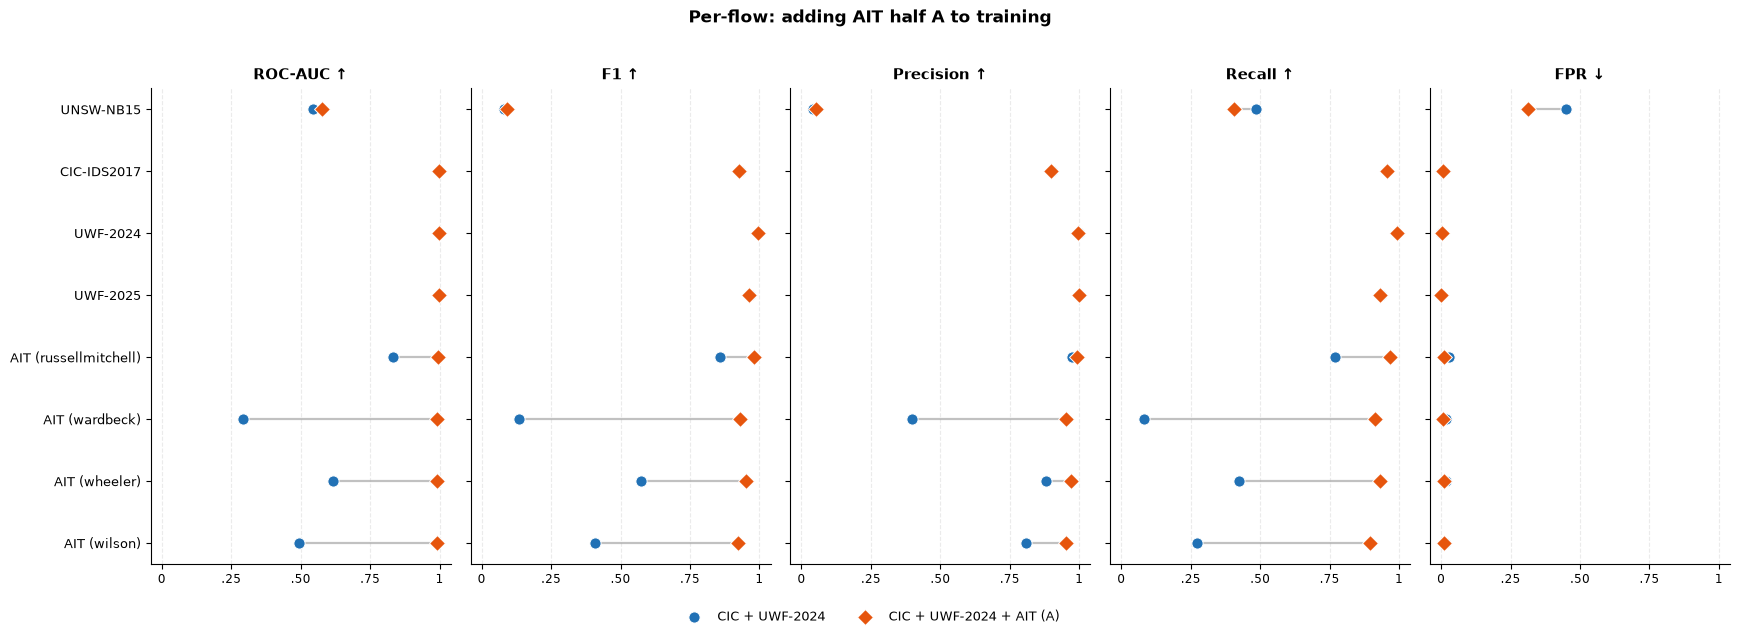

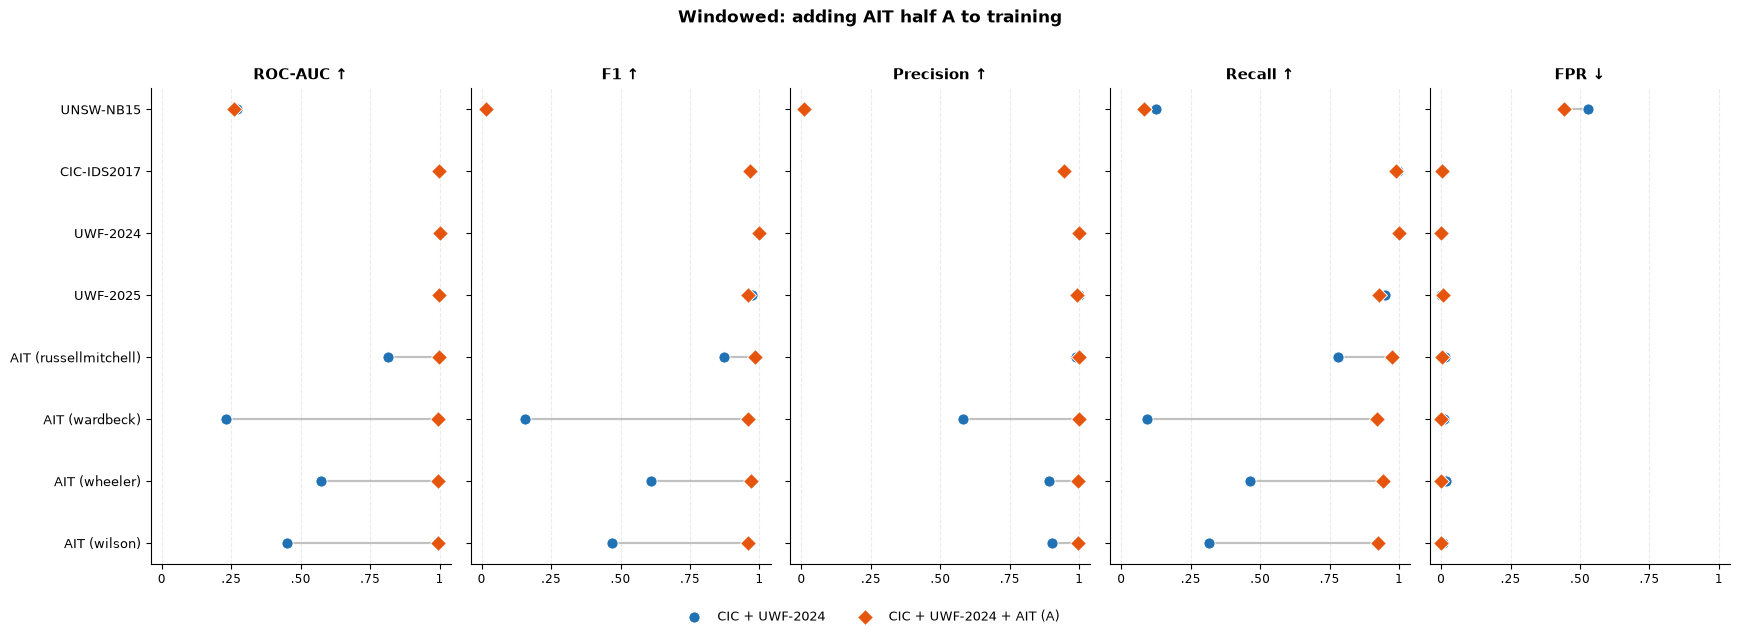

In [10]:
HALVES = {"A": ["fox", "harrison", "santos", "shaw"], "B": ["russellmitchell", "wardbeck", "wheeler", "wilson"]}
AIT_VARIANTS = {"Per-flow": PER_FLOW, "Windowed": WINDOWED}

pub_models = MODELS["CIC-IDS2017 + UWF-2024"]
raw_mix = pd.concat([
    DATA["CIC-IDS2017"]["train"][WINDOWED + ["label"]],
    DATA["UWF-2024"]["train"][WINDOWED + ["label"]],
    AIT[AIT.scenario.isin(HALVES["A"])][WINDOWED + ["label"]],
], ignore_index=True)
mix_train = subsample(raw_mix)
mix_models = {"Per-flow": (fit_zeek_model(mix_train, PER_FLOW), PER_FLOW),
              "Windowed": (fit_zeek_model(mix_train, WINDOWED), WINDOWED)}

PUB_NAMES = ["UNSW-NB15", "CIC-IDS2017", "UWF-2024", "UWF-2025"]
AIT_B_NAMES = [f"AIT ({sc})" for sc in HALVES["B"]]
TESTS = {**{n: DATA[n]["test"] for n in PUB_NAMES}, **{f"AIT ({sc})": AIT[AIT.scenario == sc] for sc in HALVES["B"]}}

rows = []
for training, models in {"CIC + UWF-2024": pub_models, "CIC + UWF-2024 + AIT (A)": mix_models}.items():
    for t, test in TESTS.items():
        for variant, (model, feats) in models.items():
            m, _ = metrics(test.label, model, test[feats])
            rows.append({"Training": training, "Test network": t, "Variant": variant, **m})

MIX_RES = pd.DataFrame(rows)
MIX_RES["Test network"] = pd.Categorical(MIX_RES["Test network"], list(TESTS))
for variant in AIT_VARIANTS:
    dot_panels(MIX_RES[MIX_RES.Variant == variant], "Training", MIX_STYLE, f"{variant}: adding AIT half A to training")

# Compact comparison table (Base = CIC+UWF-2024, +AIT = +AIT half A, Δ = change)
piv = MIX_RES.pivot_table(index=["Test network", "Variant"], columns="Training", values=["ROC-AUC", "F1", "FPR"], observed=True)
cols = {}
for m in ["ROC-AUC", "F1", "FPR"]:
    base = piv[(m, "CIC + UWF-2024")]
    plus = piv[(m, "CIC + UWF-2024 + AIT (A)")]
    cols[(m, "Base")] = base
    cols[(m, "+AIT")] = plus
    cols[(m, "Δ")] = plus - base
tbl = pd.DataFrame(cols, index=piv.index)

def avg_block(label, networks):
    sub = tbl.loc[tbl.index.get_level_values(0).isin(networks)]
    a = sub.groupby(level=1, observed=True).mean()
    a.index = pd.MultiIndex.from_product([[label], a.index], names=["Test network", "Variant"])
    return a

tbl = pd.concat([tbl, avg_block("Average (Public)", PUB_NAMES), avg_block("Average (AIT)", AIT_B_NAMES)])
avg_start = len(tbl) - 3  # 1-indexed first row of Average (Public)

fmt = {
    ("ROC-AUC", "Base"): "{:.2f}", ("ROC-AUC", "+AIT"): "{:.2f}", ("ROC-AUC", "Δ"): "{:+.2f}",
    ("F1", "Base"): "{:.2f}",      ("F1", "+AIT"): "{:.2f}",      ("F1", "Δ"): "{:+.2f}",
    ("FPR", "Base"): "{:.3f}",     ("FPR", "+AIT"): "{:.3f}",     ("FPR", "Δ"): "{:+.3f}",
}
(tbl.style
 .format(fmt)
 .set_table_styles([
     {"selector": "th", "props": [("text-align", "center"), ("padding", "5px 8px")]},
     {"selector": "th.row_heading", "props": [("text-align", "left")]},
     {"selector": "td", "props": [("text-align", "right"), ("padding", "4px 8px")]},
     {"selector": "tr:nth-child(2n) td, tr:nth-child(2n) th", "props": [("border-bottom", "1px solid #555")]},
     {"selector": "td.col0, th.col0, td.col3, th.col3, td.col6, th.col6", "props": [("border-left", "1px solid #555")]},
     {"selector": f"tbody tr:nth-child({avg_start}) td, tbody tr:nth-child({avg_start}) th",
      "props": [("border-top", "2px solid #888")]},
 ]))

- **Huge jump on all 4 unseen AIT networks (half B):** adding AIT half A lifts Windowed **F1 from 0.16–0.87 → 0.96–0.99**, **ROC-AUC from 0.23–0.81 → 0.99–1.00**, and cuts **FPR from 0.007–0.018 → 0.000–0.003**.
- **Zero cost on public datasets:** CIC-IDS2017 (F1 0.97, ROC-AUC 1.00), UWF-2024 (F1 1.00), and UWF-2025 (F1 0.96–0.97) stay virtually unchanged.
- **UNSW-NB15 stays hard** (F1 0.01–0.09) — adding AIT doesn't fix a dataset whose attack mix still isn't represented.

## Conclusion

1. **Public datasets alone don't generalize to a new enterprise network.** They catch familiar attack shapes (scans, brute force: 99–100% recall on AIT) with very low FPR, but completely miss attack types absent from training (0% recall on AIT's DNS exfiltration).
2. **Adding +10k normal rows from the target network eliminates false alarms (FPR → 0.000–0.001) and boosts ROC-AUC to 0.92–0.96**, even when F1 at threshold 0.5 looks terrible. **Next step:** calibrate the decision threshold per network using those normal rows instead of fixing it at 0.5.
3. **In-domain enterprise data beats adding more public datasets.** Adding 4 simulated enterprise networks (AIT half A) pushed unseen enterprise F1 to **0.96–0.99** (ROC-AUC **0.99–1.00**) with no regression on CIC or UWF.